# PS2: Pre-trained model (MobileNetV2) with fine-tuning for image classification
Dataset: TensorFlow flower photos (5 classes), downloaded automatically.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 5
FINE_EPOCHS = 5
IMG = (160, 160)

Data: C:\Users\choud\.keras\datasets\flower_photos_extracted\flower_photos
Found 3670 files belonging to 5 classes.


Using 2936 files for training.


Found 3670 files belonging to 5 classes.


Using 734 files for validation.


['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


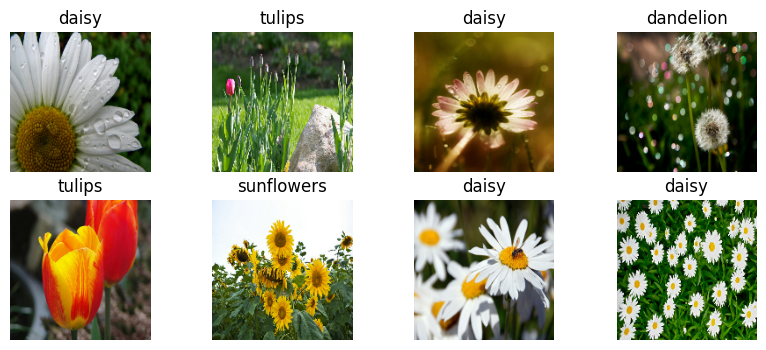

In [2]:
path = keras.utils.get_file(
    "flower_photos.tgz",
    "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
    extract=True,
)
data_dir = next(pathlib.Path(path).parent.rglob("daisy")).parent
print("Data:", data_dir)

train_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=42, image_size=IMG, batch_size=32)
val_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=42, image_size=IMG, batch_size=32)
class_names = train_ds.class_names
print(class_names)

plt.figure(figsize=(10, 4))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [3]:
base = keras.applications.MobileNetV2(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(IMG + (3,))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2)

Epoch 1/5


92/92 - 20s - 218ms/step - accuracy: 0.6516 - loss: 0.9450 - val_accuracy: 0.7970 - val_loss: 0.5205


Epoch 2/5


92/92 - 16s - 173ms/step - accuracy: 0.8324 - loss: 0.4738 - val_accuracy: 0.8365 - val_loss: 0.4637


Epoch 3/5


92/92 - 16s - 176ms/step - accuracy: 0.8604 - loss: 0.3817 - val_accuracy: 0.8501 - val_loss: 0.4198


Epoch 4/5


92/92 - 16s - 179ms/step - accuracy: 0.8910 - loss: 0.3126 - val_accuracy: 0.8447 - val_loss: 0.4268


Epoch 5/5


92/92 - 17s - 180ms/step - accuracy: 0.8917 - loss: 0.3039 - val_accuracy: 0.8610 - val_loss: 0.3960


In [4]:
# Fine-tuning: unfreeze the top layers of the base model and train with a small learning rate.
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_EPOCHS, verbose=2)

Epoch 1/5


92/92 - 26s - 280ms/step - accuracy: 0.8208 - loss: 0.4825 - val_accuracy: 0.8610 - val_loss: 0.3959


Epoch 2/5


92/92 - 20s - 219ms/step - accuracy: 0.8644 - loss: 0.3802 - val_accuracy: 0.8624 - val_loss: 0.3814


Epoch 3/5


92/92 - 20s - 222ms/step - accuracy: 0.8917 - loss: 0.3239 - val_accuracy: 0.8665 - val_loss: 0.3746


Epoch 4/5


92/92 - 20s - 220ms/step - accuracy: 0.8954 - loss: 0.3039 - val_accuracy: 0.8665 - val_loss: 0.3654


Epoch 5/5


92/92 - 19s - 210ms/step - accuracy: 0.8978 - loss: 0.2769 - val_accuracy: 0.8692 - val_loss: 0.3566


Validation accuracy: 0.8692   Validation loss: 0.3566


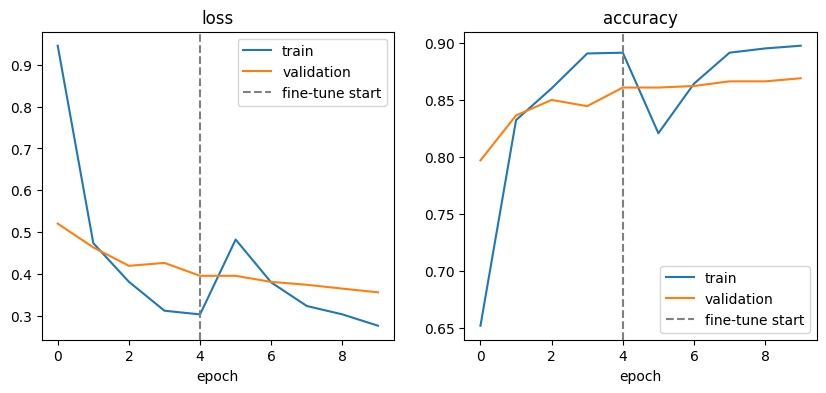

In [5]:
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy: {acc:.4f}   Validation loss: {loss:.4f}")

hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(hist[metric], label="train")
    ax[i].plot(hist["val_" + metric], label="validation")
    ax[i].axvline(EPOCHS - 1, color="gray", linestyle="--", label="fine-tune start")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()

              precision    recall  f1-score   support

       daisy     0.7752    0.9346    0.8475       107
   dandelion     0.9441    0.8848    0.9135       191
       roses     0.7891    0.8487    0.8178       119
  sunflowers     0.8750    0.8815    0.8782       135
      tulips     0.9198    0.8187    0.8663       182

    accuracy                         0.8692       734
   macro avg     0.8606    0.8737    0.8647       734
weighted avg     0.8756    0.8692    0.8702       734



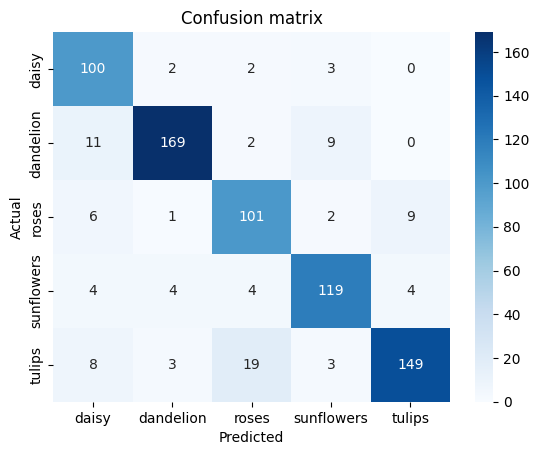

In [6]:
y_true, y_pred = [], []
for images, labels in val_ds:
    y_true.extend(labels.numpy())
    y_pred.extend(model.predict(images, verbose=0).argmax(axis=1))
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

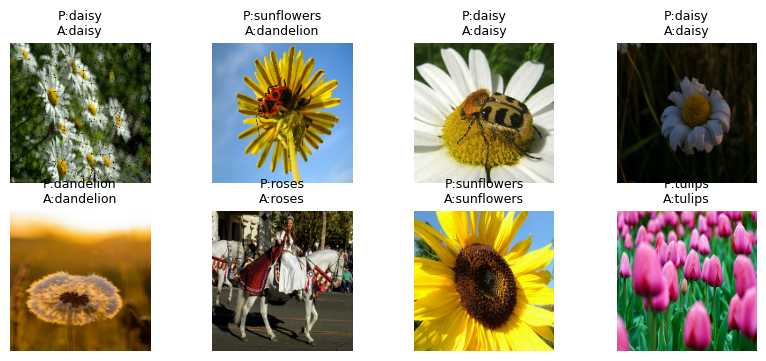

In [7]:
images, labels = next(iter(val_ds))
preds = model.predict(images, verbose=0).argmax(axis=1)
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"P:{class_names[preds[i]]}\nA:{class_names[labels[i]]}", fontsize=9)
    plt.axis("off")
plt.show()